# Re-batching: decidir tambien que ordenes van juntas

En los notebooks anteriores los batches estaban fijos: cada batch son 25 ordenes consecutivas, tal
como vienen en los datos, y lo unico que se decidia era en que ubicacion va cada SKU. Aca se decide
ademas que ordenes se recogen juntas.

**Pregunta.** Cuanto baja la caminata si los batches se arman eligiendo que ordenes van juntas, y
que slotting conviene en ese caso.

**Como se mide.** Con el simulador del paquete sobre el periodo de test, con el picker recorriendo
los pasillos en S, que es como recorre la operacion de ShipHero.

**Contenido.**
0. Datos, y tres hechos de los datos que se usan despues.
1. El recorrido en S y por que su largo depende solo de los pasillos visitados.
2. Cuatro slottings y por que se eligen.
3. El problema de re-batching, paso a paso: que se decide, cuanto espera una orden, el problema de
   optimizacion y el algoritmo, corrido a mano sobre un ejemplo.
4. Grilla de slotting por ventana, medida con la simulacion.
5. Lo mismo en otros dos depositos.
6. Lectura.

## 0. Datos

In [1]:
# Librerias y piezas del paquete.
import time
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from abs_affinity_based_slotting.config import dataset_dir
from abs_affinity_based_slotting.data import WarehouseDataLoader, split_picking_events
from abs_affinity_based_slotting.demand import TopKFilter
from abs_affinity_based_slotting.slotting import build_full_instance, Assignment
from abs_affinity_based_slotting.methods import method_registry
from abs_affinity_based_slotting.simulation import (Simulator, split_replenishments, build_event_stream,
                                                    state_from_initial_stock, state_after_history, reslot_state,
                                                    replenishment_policy_registry)
from abs_affinity_based_slotting.batching import FifoBatching, AisleCoverBatching, orders_by_arrival

pd.set_option("display.width", 160)

SIZE = "medium"                         # deposito principal (carpeta de data/v2)
OTROS = ["medium-alpha-1.3", "big"]     # depositos de la seccion 5
BATCH_SIZE = 25                         # ordenes por batch (se verifica en el hecho 2)
VENTANAS = [1, 2, 4, 8, 16]             # cuantos batches FIFO se re-arman juntos (seccion 3); 1 = FIFO

Las piezas que se usan, en el orden en que se arman:

- `split_picking_events` ordena los batches por la hora de su primera linea y deja el ultimo 20%
  como test. Los planes se calculan con train y todo se mide en test.
- `build_full_instance` arma la instancia: los indices de SKUs, ubicaciones y bays, la demanda
  $f_i$ de cada SKU (su fraccion de las lineas de train) y el costo $c_l$ de cada ubicacion (su
  distancia caminando al dock). Tambien arma la afinidad, por eso pide la metrica y el filtro; ningun
  plan de este notebook la usa.
- `state_after_history` calcula el estado real del deposito al corte entre train y test: que SKU hay
  en cada ubicacion y cuantas unidades, despues de todo lo que paso en train.
- `Simulator` reproduce sobre ese estado las lineas de picking y las reposiciones de test. Para cada
  batch suma la caminata con una politica de ruteo; aca la politica es `s_shape` (seccion 1).

Todo va en una funcion para repetirlo en la seccion 5 con otros depositos.

In [2]:
def preparar(nombre):
    # Datos, instancia, estado al corte y simulador con ruteo en S para un deposito de data/v2.
    ds = WarehouseDataLoader(dataset_dir("v2", nombre)).load_all()
    split = split_picking_events(ds.picking_events, test_size=0.2)
    instance = build_full_instance(split.train, ds.initial_stock, ds.distances, affinity_metric="jaccard",
                                   cooccurrence_col="order_id", affinity_filter=TopKFilter(k=10), normalize=True)
    # las reposiciones se cortan en el mismo momento que el picking
    replen_train, replen_test = split_replenishments(ds.replenishment_events, split.train, ds.initial_stock, split.cutoff)
    state0 = state_from_initial_stock(instance, ds.initial_stock)                     # dia cero
    eventos_train = build_event_stream(split.train, replen_train, instance)
    state_cut, _ = state_after_history(state0, eventos_train, instance)               # al corte
    sim = Simulator.from_tables(instance, ds.coordinates, routing="s_shape")
    return SimpleNamespace(nombre=nombre, ds=ds, split=split, instance=instance, replen_test=replen_test,
                           state_cut=state_cut, sim=sim, costo=sim.routing.mask_costs())


ctx = preparar(SIZE)
print(ctx.instance)
print("batches de test:", ctx.split.test["batch_id"].nunique(), "| ordenes de test:", ctx.split.test["order_id"].nunique())

SlottingInstance(n_skus=6912, n_locations=7680, n_bays=257, affinity_edges=91112)
batches de test: 1629 | ordenes de test: 40725


Tres hechos de los datos que se usan mas adelante. **Hecho 1:** cada orden tiene SKUs de un solo merchant.

In [3]:
merchants_por_orden = ctx.ds.picking_events.groupby("order_id")["merchant_account_id"].nunique()
print("merchants distintos por orden:", merchants_por_orden.value_counts().to_dict())

merchants distintos por orden: {1: 203625}


**Hecho 2:** todos los batches tienen 25 ordenes y sale uno nuevo a ritmo constante. Los datos no
traen la hora en que llega cada orden; solo el orden en que entraron a los batches.

In [4]:
# Sobre los seis meses completos: el test empieza a mitad de un dia y lo cortaria.
todo = ctx.ds.picking_events
ordenes_por_batch = todo.groupby("batch_id")["order_id"].nunique()
inicio = todo.groupby("batch_id")["timestamp"].min().sort_values()
por_dia = inicio.groupby(inicio.dt.date).size()
MINUTOS_POR_BATCH = inicio.diff().dt.total_seconds().median() / 60     # tiempo entre un batch y el siguiente
print("ordenes por batch:", ordenes_por_batch.min(), "a", ordenes_por_batch.max())
print("batches por dia:", por_dia.min(), "a", por_dia.max())
print(f"sale un batch cada {MINUTOS_POR_BATCH:.1f} minutos (mediana)")

ordenes por batch: 25 a 25
batches por dia: 45 a 45
sale un batch cada 32.0 minutos (mediana)


**Hecho 3:** al corte, cada SKU esta en exactamente una ubicacion. Asi el slotting vigente es un plan bien definido.

In [5]:
ubicaciones_por_sku = pd.Series([len(ctx.state_cut.locations_of(s)) for s in range(ctx.instance.n_skus)])
print("ubicaciones por SKU al corte:", ubicaciones_por_sku.value_counts().to_dict())
test = ctx.split.test   # de aca en adelante se trabaja con test

ubicaciones por SKU al corte: {1: 6912}


## 1. El recorrido en S

El picker sale del dock y va al frente del pasillo con picks que esta mas a la izquierda. Lo recorre
entero hasta el fondo, cruza al siguiente pasillo con picks y lo recorre entero hacia el frente, y asi
alternando. Los pasillos sin picks se saltean. Si recorrio una cantidad impar de pasillos termina en
el fondo, y vuelve al frente recorriendo el ultimo otra vez. Despues regresa al dock.

Para los pasillos visitados $S = \{a_1 < \dots < a_m\}$, el largo de ese recorrido es

$$R_S(S) = \underbrace{d_0(a_1)}_{\text{ida}} + \underbrace{m\,L}_{\text{recorrer cada pasillo}}
+ \underbrace{x_{a_m} - x_{a_1}}_{\text{cruces entre pasillos}}
+ \underbrace{[\,m \text{ impar}\,]\,L}_{\text{volver al frente}} + \underbrace{d_0(a_m)}_{\text{regreso}},
\qquad d_0(a) = |x_a - x_{\text{dock}}| + (y_0 - y_{\text{dock}}),$$

con $L$ el largo de un pasillo, $x_a$ su coordenada lateral, $y_0$ la coordenada del frente de los
pasillos y $d_0(a)$ la distancia del dock al frente del pasillo $a$. Los cruces suman
$x_{a_m} - x_{a_1}$ porque los pasillos se visitan de izquierda a derecha.

Ninguno de los terminos depende de en que bay del pasillo esta cada pick: **el largo depende solo de
que pasillos se visitan.** En el paquete es la politica `s_shape`. La que se uso en los resultados
anteriores, `snake`, vuelve al frente por el mismo pasillo; sigue disponible pero no se usa aca.

In [6]:
# La geometria, leida de la tabla de coordenadas (pulgadas).
r = ctx.sim.routing
print(f"{r.n_aisles} pasillos | largo L = {r.aisle_length:.0f} | frente en y0 = {r.front_y:.0f} | dock en {r.dock_xy}")
print("coordenada lateral x_a de cada pasillo:", r.aisle_x.tolist())

8 pasillos | largo L = 1776 | frente en y0 = 168 | dock en (0.0, -200.0)
coordenada lateral x_a de cada pasillo: [96.0, 288.0, 480.0, 672.0, 864.0, 1056.0, 1248.0, 1440.0]


La formula a mano para el pasillo 1 solo y para los pasillos 1 y 2, contra lo que calcula el paquete:

In [7]:
d0 = lambda a: abs(r.aisle_x[a] - r.dock_xy[0]) + (r.front_y - r.dock_xy[1])   # dock -> frente del pasillo a (0 = pasillo 1)
L = r.aisle_length
uno = d0(0) + 1 * L + 0 + L + d0(0)                               # m = 1, impar: vuelve recorriendo el pasillo
dos = d0(0) + 2 * L + (r.aisle_x[1] - r.aisle_x[0]) + 0 + d0(1)   # m = 2, par: termina en el frente
print("pasillo 1      : a mano", uno, "| paquete", r.distance_of_aisles([0]))
print("pasillos 1 y 2 : a mano", dos, "| paquete", r.distance_of_aisles([0, 1]))

pasillo 1      : a mano 4480.0 | paquete 4480.0
pasillos 1 y 2 : a mano 4864.0 | paquete 4864.0


Visitar un pasillo cuesta casi lo mismo que visitar dos: con uno solo hay que volver recorriendolo
otra vez. En general, cada pasillo de mas suma un largo $L$ y la paridad suma o resta otro.

Como $R_S$ depende solo del conjunto $S$, se calcula una vez para todos los conjuntos posibles. Cada
conjunto se codifica como un entero cuyo bit $a$ vale 1 si el pasillo $a$ esta en el conjunto; por
ejemplo $\{1, 3\}$ son los bits 0 y 2, o sea el entero $101_2 = 5$. Con 8 pasillos son $2^8 = 256$
conjuntos.

In [8]:
print("tabla de R_S:", len(ctx.costo), "conjuntos")
print("R_S({1, 3})          =", ctx.costo[0b101], "| directo:", r.distance_of_aisles([0, 2]))
print("R_S(todos los pasillos) =", ctx.costo[-1])

tabla de R_S: 256 conjuntos
R_S({1, 3})          = 5248.0 | directo: 5248.0
R_S(todos los pasillos) = 17824.0


## 2. Cuatro slottings

Un slotting (o plan) dice en que ubicacion va cada SKU. Los tres calculados ordenan los SKUs y las
ubicaciones y mandan el $i$-esimo SKU a la $i$-esima ubicacion. El rango de un pasillo es el costo
$c_l$ de su ubicacion mas barata, o sea que tan cerca del dock esta su frente.

| plan | orden de los SKUs | orden de las ubicaciones |
|---|---|---|
| vigente | lo que hay en el deposito al corte (hecho 3) | |
| `demand_greedy` | $f_i$ descendente | $c_l$ ascendente |
| `aisle_fill` | $f_i$ descendente | rango del pasillo, despues $c_l$ |
| `merchant_aisle_fill` | demanda total del merchant descendente, despues $f_i$ | rango del pasillo, despues $c_l$ |

Por que cada uno:

- **`demand_greedy`** es la referencia de todos los notebooks anteriores: lo mas pedido, lo mas cerca
  del dock.
- **`aisle_fill`** sale de la seccion 1. Entrar a un pasillo cuesta lo mismo si el pick esta adelante o
  al fondo, asi que no sirve repartir lo mas pedido en el frente de todos los pasillos, como hace
  `demand_greedy`. Conviene llenar un pasillo entero con lo mas pedido antes de pasar al siguiente.
- **`merchant_aisle_fill`** sale del hecho 1. Una orden nunca mezcla merchants. Si todos los SKUs de un
  merchant estan en el mismo pasillo, cada orden se recoge entrando a un solo pasillo. Los merchants
  van por demanda total para que los mas pedidos queden en los pasillos mas baratos.

Para que un merchant entre en un solo pasillo, su cantidad de SKUs tiene que caber en las ubicaciones de un pasillo:

In [9]:
inst = ctx.instance
skus_por_merchant = pd.Series(inst.merchant_ids).value_counts()
ubicaciones_por_pasillo = pd.Series(r.bay_aisle[inst.location_bay] + 1).value_counts().sort_index()
demanda_por_merchant = pd.Series(inst.demand).groupby(inst.merchant_ids).sum()
print("merchants:", len(skus_por_merchant), "| SKUs por merchant: min", skus_por_merchant.min(),
      "mediana", int(skus_por_merchant.median()), "max", skus_por_merchant.max())
print("ubicaciones por pasillo:", ubicaciones_por_pasillo.unique().tolist(),
      "| SKUs:", inst.n_skus, "| ubicaciones:", inst.n_locations)
print(f"demanda por merchant: min {demanda_por_merchant.min():.1%}, max {demanda_por_merchant.max():.1%}")

merchants: 50 | SKUs por merchant: min 107 mediana 139 max 157
ubicaciones por pasillo: [960] | SKUs: 6912 | ubicaciones: 7680
demanda por merchant: min 1.9%, max 2.1%


In [10]:
def planes_de(ctx):
    # Los cuatro planes; el vigente es la ubicacion de cada SKU en el estado real al corte.
    inst, coords = ctx.instance, ctx.ds.coordinates
    vigente = Assignment({inst.sku_id(s): inst.location_id(ctx.state_cut.primary_location(s)) for s in range(inst.n_skus)})
    return {"vigente": vigente,
            "demand_greedy": method_registry.get("demand_greedy")().solve(inst),
            "aisle_fill": method_registry.get("aisle_fill")(coords).solve(inst),
            "merchant_aisle_fill": method_registry.get("merchant_aisle_fill")(coords).solve(inst)}


def pasillo_por_sku(ctx, plan):
    # Pasillo de cada SKU bajo el plan, como posicion 0..|A|-1 (0 = pasillo 1, el mas cercano al dock).
    inst = ctx.instance
    loc = np.array([inst.location_index(plan.location_of(k)) for k in inst.sku_ids])
    return pd.Series(ctx.sim.routing.bay_aisle[inst.location_bay[loc]], index=inst.sku_ids)


planes = planes_de(ctx)
pasillos = {nombre: pasillo_por_sku(ctx, plan) for nombre, plan in planes.items()}

Que hace cada plan con las ordenes de test. *Pasillos por orden*: a cuantos pasillos distintos hay
que entrar para recoger una orden sola. *Ordenes en un solo pasillo*: cuantas se recogen entrando a
uno. *Demanda en el pasillo 1*: que parte de las lineas de train cae en el pasillo mas cercano.

In [11]:
lineas = test[["order_id", "sku"]].drop_duplicates()
resumen_planes = {}
for nombre, sku_aisle in pasillos.items():
    por_orden = lineas.assign(a=lineas["sku"].map(sku_aisle)).groupby("order_id")["a"].nunique()
    demanda = pd.Series(inst.demand).groupby(sku_aisle.to_numpy()).sum()
    resumen_planes[nombre] = {"pasillos por orden": round(por_orden.mean(), 2),
                              "ordenes en un solo pasillo": f"{(por_orden == 1).mean():.0%}",
                              "demanda en el pasillo 1": f"{demanda.get(0, 0.0):.0%}"}
pd.DataFrame(resumen_planes).T

,pasillos por orden,ordenes en un solo pasillo,demanda en el pasillo 1
vigente,2.94,4%,14%
demand_greedy,2.4,12%,51%
aisle_fill,1.94,30%,70%
merchant_aisle_fill,1.04,96%,14%


Con `merchant_aisle_fill` no todas las ordenes caen en un pasillo porque algunos merchants quedan partidos en el borde entre dos pasillos:

In [12]:
pasillos_por_merchant = pasillos["merchant_aisle_fill"].groupby(inst.merchant_ids).nunique()
print("merchants en un pasillo:", int((pasillos_por_merchant == 1).sum()), "| partidos en dos:", int((pasillos_por_merchant == 2).sum()))

merchants en un pasillo: 44 | partidos en dos: 6


## 3. El problema de re-batching

Esta seccion va de a poco:

- 3.1 Como se arman los batches hoy.
- 3.2 Que se decide y que queda fijo.
- 3.3 Por que eso puede acortar la caminata.
- 3.4 Cuanto espera una orden.
- 3.5 El problema de optimizacion.
- 3.6 Primer paso del algoritmo: construir.
- 3.7 Segundo paso: intercambiar.
- 3.8 Como se calcula rapido.

Todo se muestra sobre un mismo ejemplo: las primeras 100 ordenes de test con el plan
`merchant_aisle_fill`.

### 3.1 Como se arman los batches hoy

Las ordenes llegan una detras de otra. Cada vez que se juntan 25 forman un batch: el primero son las
ordenes 1 a 25, el segundo las 26 a 50, y asi. Eso es FIFO. La clase `FifoBatching` del paquete hace
exactamente eso, ordenando las ordenes por la hora de su primera linea; el chequeo de abajo confirma
que arma los mismos batches que los datos.

In [13]:
fifo = FifoBatching(BATCH_SIZE).make_batches(test)
batch_original = test.drop_duplicates("order_id").set_index("order_id")["batch_id"]
originales_por_batch = (fifo.drop_duplicates("order_id")
                        .assign(original=lambda t: t["order_id"].map(batch_original))
                        .groupby("batch_id")["original"].nunique())
print(f"batches FIFO que coinciden con un batch de los datos: {(originales_por_batch == 1).mean():.2%}")

batches FIFO que coinciden con un batch de los datos: 100.00%


### 3.2 Que se decide y que queda fijo

En vez de cerrar un batch apenas hay 25 ordenes, se espera a juntar $W \cdot 25$ ordenes
consecutivas, y recien ahi se decide como repartirlas en $W$ batches de 25. A ese grupo se lo llama
**pool** y a $W$, **ventana**. Con $W = 4$, el pool son 100 ordenes que se reparten en 4 batches. Con
$W = 1$ el pool es un solo batch y no hay nada que decidir: es FIFO.

Queda fijo todo lo demas:

- las mismas ordenes, con sus mismas lineas;
- 25 ordenes por batch (hecho 2; ShipHero arma batches de hasta 25 ordenes, una por tote);
- la misma cantidad de batches;
- el slotting: el re-batching solo lee en que pasillo esta cada SKU.

Lo unico que cambia es que ordenes van juntas.

### 3.3 Por que eso puede acortar la caminata

Para cada orden $o$, $A(o)$ es el conjunto de pasillos donde estan sus SKUs segun el plan. Un batch
tiene que entrar a todos los pasillos que necesita alguna de sus ordenes, o sea a la union de sus
$A(o)$. Por la seccion 1, su caminata depende solo de esa union.

Una orden concreta del ejemplo, con el pasillo de cada SKU:

In [14]:
sa = pasillos["merchant_aisle_fill"]                        # pasillo de cada SKU (0 = pasillo 1)
pool_ejemplo = orders_by_arrival(test)[:4 * BATCH_SIZE]     # las primeras 100 ordenes de test
lineas_pool = test[test["order_id"].isin(pool_ejemplo)]

# A(o) de cada orden del ejemplo, con los pasillos numerados desde 1.
A = (lineas_pool.assign(pasillo=lineas_pool["sku"].map(sa) + 1)
     .groupby("order_id")["pasillo"].apply(lambda s: frozenset(int(a) for a in s))
     .reindex(pool_ejemplo))
RS = lambda pasillos_1: r.distance_of_aisles([a - 1 for a in pasillos_1])   # R_S con pasillos numerados desde 1

o = pool_ejemplo[0]
print(lineas_pool.loc[lineas_pool["order_id"] == o, ["order_id", "sku", "merchant_account_id"]]
      .assign(pasillo=lambda t: t["sku"].map(sa) + 1).to_string(index=False))
print("A(o) =", sorted(A[o]))

       order_id       sku merchant_account_id  pasillo
ORDER-000162925 SKU-02046             MER-003        6
ORDER-000162925 SKU-03327             MER-003        6
ORDER-000162925 SKU-03642             MER-003        6
ORDER-000162925 SKU-04914             MER-003        6
A(o) = [6]


Que pasillos necesitan las 100 ordenes del ejemplo, agrupadas por su $A(o)$:

In [15]:
A.map(lambda s: tuple(sorted(s))).value_counts().rename("ordenes").rename_axis("A(o)").to_frame().T

A(o),"(6,)","(3,)","(5,)","(1,)","(7,)","(4,)","(2,)","(6, 7)","(7, 8)","(8,)","(3, 4)"
ordenes,20,17,16,16,9,9,8,2,1,1,1


Casi todas las ordenes necesitan un solo pasillo, pero con FIFO cada batch junta 25 ordenes
cualesquiera, y entre todas necesitan casi todos los pasillos:

In [16]:
def describir(picking):
    # Pasillos visitados (numerados desde 1) y caminata en S de cada batch.
    g = picking.assign(pasillo=picking["sku"].map(sa)).groupby("batch_id")["pasillo"]
    return pd.DataFrame({"pasillos visitados": g.apply(lambda s: sorted(int(a) + 1 for a in set(s))),
                         "R_S": g.apply(lambda s: r.distance_of_aisles(s.to_numpy()))})


fifo_ejemplo = describir(FifoBatching(BATCH_SIZE).make_batches(lineas_pool))
print(fifo_ejemplo.to_string())
print("caminata total del pool con FIFO:", fifo_ejemplo["R_S"].sum())

                   pasillos visitados      R_S
batch_id                                      
FIFO-000000     [1, 2, 3, 4, 5, 6, 7]  17440.0
FIFO-000001  [1, 2, 3, 4, 5, 6, 7, 8]  17824.0
FIFO-000002  [1, 2, 3, 4, 5, 6, 7, 8]  17824.0
FIFO-000003     [1, 2, 3, 4, 5, 6, 7]  17440.0
caminata total del pool con FIFO: 70528.0


Si en cambio se juntan ordenes que necesitan los mismos pasillos, cada batch entra a menos. Decidir
como juntarlas es el problema de 3.5.

### 3.4 Cuanto espera una orden

Juntar mas ordenes antes de decidir tiene un costo: la orden espera mas. Para medirlo hace falta saber
cuando llega cada orden, y los datos no lo traen (hecho 2). Por eso se fija una regla y se la dice:

- **Llegada.** Las ordenes llegan en el orden de la FIFO y parejas, 25 por **franja**. Una franja es
  el tiempo entre un batch y el siguiente; en medium, 32 minutos (hecho 2).
- **Salida.** Un pool se completa cuando llega su ultima orden. Desde ahi sus $W$ batches salen de a
  uno por franja, el mismo ritmo que con FIFO, para que los pickers tengan la misma carga. Sale
  primero el batch que tiene la orden que llego antes.

Un ejemplo con $W = 2$, contando el tiempo en franjas desde que llega la orden 1:

| | orden 1 | orden 26 |
|---|---|---|
| llega en | 0 | 1 |
| con FIFO sale en | 1 (al llegar la orden 25) | 2 (al llegar la orden 50) |
| con $W = 2$ sale en | 2 (se completa el pool con la orden 50) | 2 o 3, segun su batch salga primero o segundo |

En general, para la orden que llega en el lugar $r$ (contando desde 0), en el pool $p$, en un batch
que sale en el turno $t$ ($t = 0$ el primero), la espera en franjas es

$$\text{espera}(o) = \underbrace{\frac{r_{\max}(p) + 1}{25}}_{\text{se completa el pool}} + \underbrace{t}_{\text{turno de su batch}} - \underbrace{\frac{r}{25}}_{\text{llega}},$$

con $r_{\max}(p)$ el lugar de la ultima orden del pool $p$.

In [17]:
def esperas(picking, ventana):
    # Espera de cada orden, en franjas, con la regla de arriba.
    orden = orders_by_arrival(picking)
    lugar = pd.Series(np.arange(len(orden)), index=orden)                        # r
    batch = picking.drop_duplicates("order_id").set_index("order_id")["batch_id"].reindex(orden)
    pool = lugar // (ventana * BATCH_SIZE)                                       # p
    completo = (lugar.groupby(pool).transform("max") + 1) / BATCH_SIZE           # (r_max(p) + 1) / 25
    mas_vieja = lugar.groupby(batch).min()                                       # orden mas vieja de cada batch
    turno = mas_vieja.groupby(pool.groupby(batch).first()).rank(method="first") - 1   # t
    return completo + batch.map(turno) - lugar / BATCH_SIZE


# Con FIFO la espera va de 1/25 de franja (la orden 25 de su batch) a 1 franja (la orden 1).
e = esperas(FifoBatching(BATCH_SIZE).make_batches(test), 1)
print(f"FIFO: espera minima {e.min():.2f}, maxima {e.max():.2f} franjas")

FIFO: espera minima 0.04, maxima 1.00 franjas


### 3.5 El problema de optimizacion

**Datos de un pool.** El conjunto de ordenes $P$, con $|P| = 25\,W$; los batches $K = \{1, \dots, W\}$;
y $A(o)$ para cada orden (3.3).

**Variables.** Una binaria por cada orden y cada batch:
$$z_{ok} = \begin{cases} 1 & \text{si la orden } o \text{ va al batch } k, \\ 0 & \text{si no.} \end{cases}$$

**Pasillos de un batch.** La union de los pasillos de sus ordenes:
$$M_k = \bigcup_{o \,:\, z_{ok} = 1} A(o).$$

**Caminata de un batch.** El recorrido en S sobre esos pasillos, $R_S(M_k)$, con la formula de la
seccion 1.

**Problema.**
$$
\begin{aligned}
\min_{z}\quad & \sum_{k \in K} R_S(M_k)
    && \text{(caminata total del pool)} \\
\text{s.a.}\quad & \sum_{k \in K} z_{ok} = 1 && \forall o \in P \quad \text{(cada orden va a un batch)} \\
& \sum_{o \in P} z_{ok} = 25 && \forall k \in K \quad \text{(cada batch tiene 25 ordenes)} \\
& z_{ok} \in \{0,1\}.
\end{aligned}
$$

El ultimo pool del periodo puede tener menos de $25\,W$ ordenes; ahi el ultimo batch queda mas chico,
igual que con FIFO.

**Por que no se resuelve exacto.** Dos razones. La primera es el tamano: la cantidad de formas de
repartir el pool es la de abajo. La segunda es que $R_S(M_k)$ no es lineal en $z$: depende de que
pasillos hay en una union, de cuantos son y de si son una cantidad par o impar. Se puede linealizar
con variables $y_{ka}$ (el batch $k$ entra al pasillo $a$), como el MIP del notebook 03, pero ese MIP
ya quedaba con gaps de 60 a 90% despues de 10 minutos. Por eso se usa una heuristica, que no garantiza
el optimo.

In [18]:
from math import factorial

# Formas de repartir 25 W ordenes en W batches de 25 (los batches no tienen nombre: se divide por W!).
for W in (2, 4, 16):
    n = 25 * W
    formas = factorial(n) // (factorial(25) ** W * factorial(W))
    print(f"W = {W:2d}: {n:3d} ordenes, unas 10^{len(str(formas)) - 1} formas")

W =  2:  50 ordenes, unas 10^13 formas
W =  4: 100 ordenes, unas 10^55 formas
W = 16: 400 ordenes, unas 10^452 formas


### 3.6 Primer paso del algoritmo: construir

Los batches del pool se arman de a uno.

1. **Semilla.** Se abre el batch con la orden libre que sola pide mas caminata:
   $$o^\ast = \arg\max_{o \text{ libre}} R_S\big(A(o)\big), \qquad M \leftarrow A(o^\ast).$$
   Abrir con una orden semilla y hacer crecer el batch es la familia de algoritmos *seed* de order
   batching (Yang 2020 y Deng 2025, en `docs/lecturas-2026-10.md`). Que la semilla sea la orden mas
   cara es una eleccion de este trabajo: es la orden con menos companeras que no le agreguen pasillos,
   y si quedara para el final terminaria en un batch que no le conviene.
2. **Crecer.** Para cada orden libre se calcula cuanto agregaria a la caminata del batch,
   $$\Delta(o \mid M) = R_S\big(M \cup A(o)\big) - R_S(M),$$
   y se agrega la de menor $\Delta$; en un empate, la que llego antes. Se actualiza
   $M \leftarrow M \cup A(o)$ y se repite hasta tener 25 ordenes.
3. Se abre el batch siguiente con las ordenes que quedan libres.

Algunos valores de $\Delta$, para un batch que ya entra al pasillo 3:

In [19]:
M = {3}
for candidata in ({3}, {4}, {1, 6}):
    print(f"A(o) = {sorted(candidata)}: R_S(M u A(o)) = {RS(M | candidata):6.0f}, Delta = {RS(M | candidata) - RS(M):6.0f}")

A(o) = [3]: R_S(M u A(o)) =   5248, Delta =      0
A(o) = [4]: R_S(M u A(o)) =   5632, Delta =    384
A(o) = [1, 6]: R_S(M u A(o)) =   9952, Delta =   4704


$\Delta$ se calcula con $R_S$ y no contando pasillos nuevos porque agregar un pasillo puede no costar
nada. Con los pasillos 1, 3 y 5 el picker termina al fondo del 5 y vuelve recorriendolo otra vez; si
se agrega el 4, sube por el 4, baja por el 5 y termina en el frente, con la misma distancia:

In [20]:
print("R_S({1, 3, 5})    =", RS({1, 3, 5}))
print("R_S({1, 3, 4, 5}) =", RS({1, 3, 4, 5}))

R_S({1, 3, 5})    = 9568.0
R_S({1, 3, 4, 5}) = 9568.0


El primer batch del ejemplo, construido paso a paso con el codigo mas simple posible (conjuntos de
Python). Cada fila es una orden que entra al batch.

In [21]:
libres = list(pool_ejemplo)                                    # en orden de llegada: los empates los gana la primera
semilla = max(libres, key=lambda o: RS(A[o]))                  # paso 1
M, batch = set(A[semilla]), [semilla]
libres.remove(semilla)
traza = [{"orden": semilla, "A(o)": sorted(A[semilla]), "Delta": None, "pasillos del batch": sorted(M), "R_S": RS(M)}]
while len(batch) < BATCH_SIZE:                                 # paso 2
    delta = {o: RS(M | A[o]) - RS(M) for o in libres}
    elegida = min(libres, key=delta.get)
    M |= A[elegida]
    batch.append(elegida)
    libres.remove(elegida)
    traza.append({"orden": elegida, "A(o)": sorted(A[elegida]), "Delta": delta[elegida],
                  "pasillos del batch": sorted(M), "R_S": RS(M)})
pd.DataFrame(traza).rename_axis("paso").rename(index=lambda i: i + 1)

,orden,A(o),Delta,pasillos del batch,R_S
paso,,,,,
1,ORDER-000162949,"[7, 8]",NaN,"[7, 8]",7168.0
2,ORDER-000162921,[7],0.0,"[7, 8]",7168.0
3,ORDER-000162905,[7],0.0,"[7, 8]",7168.0
4,ORDER-000162922,[7],0.0,"[7, 8]",7168.0
5,ORDER-000162911,[7],0.0,"[7, 8]",7168.0
6,ORDER-000162935,[7],0.0,"[7, 8]",7168.0
7,ORDER-000162966,[7],0.0,"[7, 8]",7168.0
8,ORDER-000162964,[7],0.0,"[7, 8]",7168.0
9,ORDER-000162960,[7],0.0,"[7, 8]",7168.0


Que muestra la traza:

- **Semilla.** Una orden que necesita los pasillos 7 y 8 y camina 7.168 sola, el maximo del pool.
  Empata con la unica orden que necesita solo el pasillo 8, y gana por haber llegado antes.
- **Pasos 2 a 11.** Entran ordenes que solo necesitan el 7 o el 8. Tienen $\Delta = 0$: no agregan
  caminata.
- **Paso 12.** Ya no queda ninguna orden libre con $\Delta = 0$. La mas barata agrega el pasillo 6, con
  $\Delta = 3.552 = 2L$: el batch pasa de 2 a 3 pasillos, uno mas para recorrer y, por ser impar, uno
  mas para volver.
- **Paso 14.** Entra el pasillo 5 sin costo, por el efecto de paridad de arriba: con 4 pasillos ya no
  hay que volver recorriendo el ultimo.

El paquete (`AisleCoverBatching` sin el paso de intercambios) arma el mismo primer batch:

In [22]:
construido = AisleCoverBatching(sa, ctx.costo, batch_size=BATCH_SIZE, window=4, max_passes=0).make_batches(lineas_pool)
primer_batch = set(construido.loc[construido["batch_id"] == "AC-00000-000", "order_id"])
print("mismo primer batch:", primer_batch == set(batch))
print(describir(construido).to_string())
print("caminata total del pool despues de construir:", describir(construido)["R_S"].sum())

mismo primer batch: True
             pasillos visitados      R_S
batch_id                                
AC-00000-000       [5, 6, 7, 8]  10720.0
AC-00000-001       [3, 4, 6, 7]  10336.0
AC-00000-002             [1, 5]   6016.0
AC-00000-003       [2, 3, 4, 5]   9568.0
caminata total del pool despues de construir: 36640.0


### 3.7 Segundo paso: intercambiar

Con los batches construidos, se prueba cambiar una orden $o$ del batch $k_1$ por una orden $o'$ del
batch $k_2$.

**Pasillos de un batch sin una de sus ordenes.** No alcanza con sacar $A(o)$ de $M_{k_1}$, porque otra
orden del batch puede usar esos mismos pasillos. Hay que rehacer la union sin $o$:
$$M_{k_1}^{-o} = \bigcup_{u \in k_1,\; u \neq o} A(u).$$

**Despues del intercambio,** $k_1$ pierde $o$ y gana $o'$, y $k_2$ al reves:
$$M_{k_1}' = M_{k_1}^{-o} \cup A(o'), \qquad M_{k_2}' = M_{k_2}^{-o'} \cup A(o).$$

**Cuanto cambia la caminata:**
$$\delta(o, o') = R_S(M_{k_1}') + R_S(M_{k_2}') - R_S(M_{k_1}) - R_S(M_{k_2}).$$

**Regla.** Para cada orden $o$, se busca la $o'$ de otro batch con menor $\delta$, y si $\delta < 0$
se hace el intercambio. Se recorren todas las ordenes del pool; se repite hasta una pasada sin
intercambios, con un tope de 20 pasadas.

**Por que termina y que garantiza.** Cada intercambio baja la caminata total, asi que nunca se vuelve
a un reparto anterior, y los repartos son finitos. Al terminar ningun intercambio de dos ordenes
mejora: es un optimo local. No hay garantia de que sea el optimo del problema de 3.5.

Los intercambios que mejoran el reparto construido del ejemplo, calculados uno por uno con la formula
de $\delta$:

In [23]:
from itertools import combinations

grupos = construido.drop_duplicates("order_id").groupby("batch_id")["order_id"].apply(list)
union = lambda ordenes: frozenset().union(*(A[u] for u in ordenes))

candidatos = []
for k1, k2 in combinations(grupos.index, 2):
    antes = RS(union(grupos[k1])) + RS(union(grupos[k2]))
    for o in grupos[k1]:
        sin_o = union([u for u in grupos[k1] if u != o])                # M_{k1}^{-o}
        for o2 in grupos[k2]:
            sin_o2 = union([u for u in grupos[k2] if u != o2])          # M_{k2}^{-o'}
            d = RS(sin_o | A[o2]) + RS(sin_o2 | A[o]) - antes           # delta(o, o')
            if d < 0:
                candidatos.append({"o": o, "A(o)": sorted(A[o]), "batch de o": k1,
                                   "o'": o2, "A(o')": sorted(A[o2]), "batch de o'": k2, "delta": d})
print("intercambios que bajan la caminata:", len(candidatos))
pd.DataFrame(candidatos).sort_values("delta").head(5)

intercambios que bajan la caminata: 29


,o,A(o),batch de o,o',A(o'),batch de o',delta
0,ORDER-000162925,[6],AC-00000-000,ORDER-000162938,"[6, 7]",AC-00000-001,-384.0
1,ORDER-000162912,[6],AC-00000-000,ORDER-000162938,"[6, 7]",AC-00000-001,-384.0
2,ORDER-000162920,[5],AC-00000-000,ORDER-000162938,"[6, 7]",AC-00000-001,-384.0
3,ORDER-000162908,[6],AC-00000-000,ORDER-000162938,"[6, 7]",AC-00000-001,-384.0
4,ORDER-000162904,[6],AC-00000-000,ORDER-000162938,"[6, 7]",AC-00000-001,-384.0


Los mejores intercambios llevan al primer batch, que ya entra a los pasillos 6 y 7, la orden del
segundo batch que necesita esos dos pasillos. A cambio el segundo batch recibe una orden que necesita
el 5 o el 6. Asi el segundo batch deja de entrar al pasillo 7 y la caminata baja 384 pulgadas.

El reparto final del paquete, con construccion e intercambios:

In [24]:
final = AisleCoverBatching(sa, ctx.costo, batch_size=BATCH_SIZE, window=4).make_batches(lineas_pool)
print(describir(final).to_string())
print("caminata total del pool: FIFO", fifo_ejemplo["R_S"].sum(),
      "| construido", describir(construido)["R_S"].sum(), "| final", describir(final)["R_S"].sum())

             pasillos visitados      R_S
batch_id                                
AC-00000-000       [5, 6, 7, 8]  10720.0
AC-00000-001       [3, 4, 5, 6]   9952.0
AC-00000-002             [1, 5]   6016.0
AC-00000-003          [2, 3, 4]   9184.0
caminata total del pool: FIFO 70528.0 | construido 36640.0 | final 35872.0


En este pool, la construccion baja la caminata total de 70.528 a 36.640 pulgadas, casi a la mitad.
Los intercambios la bajan a 35.872, un 2% mas. Los batches pasan de entrar a 7 u 8 pasillos a entrar
a 4, 4, 2 y 3.

### 3.8 Como se calcula rapido

Con conjuntos de Python, como en 3.6 y 3.7, todo el periodo de test tardaria demasiado. El paquete
hace las mismas cuentas con tres recursos:

- **Mascaras.** Cada $A(o)$ es un entero con un bit por pasillo (seccion 1), y la union de conjuntos
  es el *o* bit a bit.
- **Tabla de $R_S$.** $R_S$ de cualquier conjunto se lee de la tabla de la seccion 1, sin recalcular la
  formula.
- **Conteos por pasillo.** Para cada batch $k$ y pasillo $a$ se guarda $c_{ka}$, cuantas ordenes del
  batch necesitan ese pasillo. Asi el batch sin la orden $o$ entra a
  $$M_k^{-o} = \{\,a : c_{ka} - [\,a \in A(o)\,] > 0\,\},$$
  y no hace falta rehacer la union recorriendo las 25 ordenes.

Con eso $\delta(o, o')$ son cuatro lecturas de la tabla, y se calcula para todas las $o'$ del pool a la
vez. La seccion 4 muestra que re-armar todo el test tarda unos 2 segundos.

## 4. Grilla: slotting por ventana, medida con la simulacion

Cada corrida hace, en orden:

1. Re-arma los batches de test con la ventana dada.
2. Aplica el plan al estado del corte: cada SKU se muda a su ubicacion del plan con las unidades que
   tenia (`reslot_state`). El costo de esa mudanza no se cuenta.
3. Simula el periodo de test. Cada reposicion va a la ubicacion del SKU en el plan (politica `home`),
   y cada batch se camina en S.

Los cuatro planes se simulan igual, asi que lo unico que cambia entre filas es el plan y los batches.
El vigente tambien usa `home`, que lo mantiene como estaba al corte. En el notebook 02 se simulaba con
reposicion aleatoria; aca no, para que la comparacion sea solo de plan y batching.

Las lineas conservan su hora de los datos. El simulador usa la hora solo para intercalar las
reposiciones con los picks. Si al re-armar algun pick quedara antes de la reposicion que lo abastece,
apareceria como faltante; la columna `faltantes` lo controla.

In [25]:
def simular(ctx, plan, sku_aisle, ventana, minutos_por_batch):
    # Una corrida: re-batching, simulacion y espera de las ordenes. Devuelve una fila de resultados.
    t0 = time.time()
    batching = AisleCoverBatching(sku_aisle, ctx.costo, batch_size=BATCH_SIZE, window=ventana)
    picking = batching.make_batches(ctx.split.test)                         # mismas lineas, otro batch_id
    segundos = time.time() - t0

    eventos = build_event_stream(picking, ctx.replen_test, ctx.instance)
    estado = reslot_state(ctx.state_cut, plan, ctx.instance)                # paso 2
    res = ctx.sim.run(estado, eventos, replenishment_policy_registry.get("home")(), planned=plan)

    n = picking["batch_id"].nunique()
    espera = esperas(picking, ventana) * minutos_por_batch
    pasillos_por_batch = picking.assign(a=picking["sku"].map(sku_aisle)).groupby("batch_id")["a"].nunique().mean()
    return {"R_S media": res.route_metrics.mean_batch_distance,             # caminata media por batch, simulada
            "pasillos por batch": pasillos_por_batch,
            "espera media (min)": espera.mean(), "espera max (min)": espera.max(),
            "solo construccion": batching.stats_["construction"] / n,      # caminata del algoritmo sin la mejora
            "estatico": batching.stats_["local_search"] / n,               # caminata que el algoritmo calcula
            "faltantes": res.shortfall_lines, "mudanzas": res.n_relocations,
            "segundos batching": round(segundos, 1)}


filas = [{"plan": nombre, "ventana": w, **simular(ctx, planes[nombre], pasillos[nombre], w, MINUTOS_POR_BATCH)}
         for nombre in planes for w in VENTANAS]
grilla = pd.DataFrame(filas)
base = grilla.query("plan == 'demand_greedy' and ventana == 1")["R_S media"].item()   # referencia: greedy con FIFO
grilla["vs greedy FIFO"] = (grilla["R_S media"] / base - 1) * 100

Tres controles. Si la simulacion coincide con la cuenta del algoritmo, ningun SKU cambio de pasillo
durante el test. Las mudanzas cuentan reposiciones que fueron a otra ubicacion que la del plan. Los
faltantes cuentan lineas sin stock.

In [26]:
print("diferencia maxima entre simulacion y cuenta del algoritmo:", round((grilla["R_S media"] - grilla["estatico"]).abs().max(), 3))
print("mudanzas:", grilla["mudanzas"].sum(), "| faltantes:", grilla["faltantes"].sum())

diferencia maxima entre simulacion y cuenta del algoritmo: 0.0
mudanzas: 0 | faltantes: 0


Cuanto espera una orden segun la ventana (no depende del plan). Con FIFO ya hay espera: la de juntar las 25 ordenes.

In [27]:
grilla.query("plan == 'demand_greedy'").set_index("ventana")[["espera media (min)", "espera max (min)"]].round(0)

,espera media (min),espera max (min)
ventana,,
1,17.0,32.0
2,49.0,95.0
4,113.0,220.0
8,240.0,462.0
16,496.0,881.0


Caminata media en S por batch, en pulgadas. Filas: plan; columnas: ventana.

In [28]:
grilla.pivot(index="plan", columns="ventana", values="R_S media").round(0).loc[list(planes)]

ventana,1,2,4,8,16
plan,,,,,
vigente,17824.0,17501.0,15893.0,15097.0,14662.0
demand_greedy,17624.0,15153.0,13871.0,12891.0,12072.0
aisle_fill,16748.0,13423.0,11964.0,11177.0,10721.0
merchant_aisle_fill,17278.0,12049.0,9542.0,7530.0,6856.0


La misma tabla como diferencia contra `demand_greedy` con FIFO, la referencia de los notebooks anteriores.

In [29]:
(grilla.pivot(index="plan", columns="ventana", values="vs greedy FIFO").round(1).astype(str) + "%").loc[list(planes)]

ventana,1,2,4,8,16
plan,,,,,
vigente,1.1%,-0.7%,-9.8%,-14.3%,-16.8%
demand_greedy,0.0%,-14.0%,-21.3%,-26.9%,-31.5%
aisle_fill,-5.0%,-23.8%,-32.1%,-36.6%,-39.2%
merchant_aisle_fill,-2.0%,-31.6%,-45.9%,-57.3%,-61.1%


Pasillos visitados por batch, de 8. Explica la tabla anterior, porque $R_S$ depende de los pasillos visitados.

In [30]:
grilla.pivot(index="plan", columns="ventana", values="pasillos por batch").round(2).loc[list(planes)]

ventana,1,2,4,8,16
plan,,,,,
vigente,8.00,7.73,6.86,6.44,6.22
demand_greedy,7.63,6.38,5.73,5.21,4.79
aisle_fill,6.97,5.55,4.85,4.42,4.16
merchant_aisle_fill,7.28,4.79,3.55,2.53,2.19


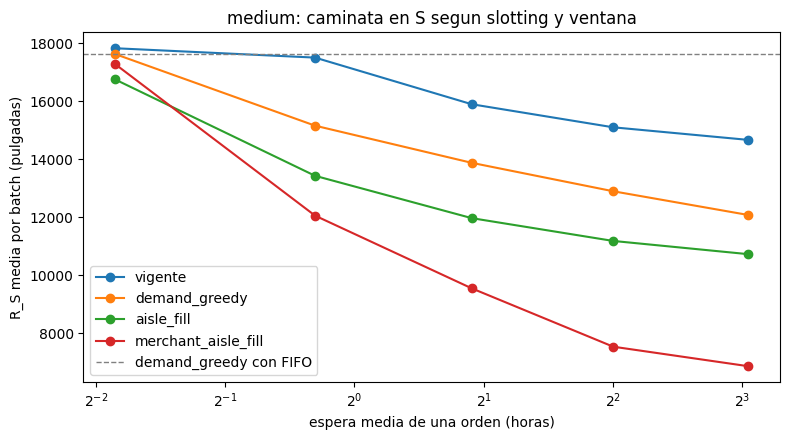

In [31]:
# Caminata media contra la espera media de una orden, por plan. Cada punto es una ventana.
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre in planes:
    g = grilla.query("plan == @nombre")
    ax.plot(g["espera media (min)"] / 60, g["R_S media"], marker="o", label=nombre)
ax.axhline(base, color="gray", ls="--", lw=1, label="demand_greedy con FIFO")
ax.set_xscale("log", base=2)
ax.set_xlabel("espera media de una orden (horas)")
ax.set_ylabel("R_S media por batch (pulgadas)")
ax.set_title(f"{SIZE}: caminata en S segun slotting y ventana")
ax.legend()
plt.tight_layout()
plt.show()

Cuanto aporta cada paso del algoritmo: la construccion sola, contra construccion mas intercambios.

In [32]:
pasos = grilla.query("ventana > 1")[["plan", "ventana", "solo construccion", "R_S media", "segundos batching"]].copy()
pasos["mejora de los intercambios"] = ((pasos["R_S media"] / pasos["solo construccion"] - 1) * 100).round(1).astype(str) + "%"
pasos.round(0)

,plan,ventana,solo construccion,R_S media,segundos batching,mejora de los intercambios
1,vigente,2,17501.0,17501.0,2.0,0.0%
2,vigente,4,15908.0,15893.0,2.0,-0.1%
3,vigente,8,15117.0,15097.0,2.0,-0.1%
4,vigente,16,14687.0,14662.0,2.0,-0.2%
6,demand_greedy,2,15408.0,15153.0,2.0,-1.7%
7,demand_greedy,4,14202.0,13871.0,2.0,-2.3%
8,demand_greedy,8,13197.0,12891.0,2.0,-2.3%
9,demand_greedy,16,12410.0,12072.0,2.0,-2.7%
11,aisle_fill,2,13869.0,13423.0,2.0,-3.2%
12,aisle_fill,4,12404.0,11964.0,2.0,-3.6%


## 5. Otros depositos

`medium-alpha-1.3` es el mismo deposito `medium` generado con la demanda mas concentrada en pocos
SKUs (parametro `pareto_alpha` del generador). `big` tiene 16 pasillos. Se repiten los tres planes
calculados con tres ventanas. Primero, que cambia en los datos:

In [33]:
import json

def perfil(nombre):
    # Concentracion de la demanda y ritmo de batches de un deposito.
    pe = pd.read_parquet(dataset_dir("v2", nombre) / "picking_events.parquet", columns=["batch_id", "sku", "timestamp"])
    acumulada = pe["sku"].value_counts(normalize=True).cumsum()
    inicio = pe.groupby("batch_id")["timestamp"].min().sort_values()
    manifest = json.loads((dataset_dir("v2", nombre) / "manifest.json").read_text())
    return {"pasillos": manifest["preset"]["num_aisles"], "pareto_alpha": manifest.get("pareto_alpha", "(no figura)"),
            "SKUs": pe["sku"].nunique(), "SKUs para el 50% de las lineas": int((acumulada <= 0.5).sum()),
            "SKUs para el 80% de las lineas": int((acumulada <= 0.8).sum()),
            "minutos entre batches": round(inicio.diff().dt.total_seconds().median() / 60, 1),
            "pickers": manifest["preset"]["num_pickers"]}

pd.DataFrame({n: perfil(n) for n in [SIZE] + OTROS})

,medium,medium-alpha-1.3,big
pasillos,8,8.0,16
pareto_alpha,(no figura),1.3,(no figura)
SKUs,6912,6912.0,24880
SKUs para el 50% de las lineas,318,227.0,755
SKUs para el 80% de las lineas,1733,1222.0,4957
minutos entre batches,32.0,32.0,14.4
pickers,20,20.0,60


In [34]:
otros = []
for nombre_deposito in OTROS:
    c = preparar(nombre_deposito)
    minutos = perfil(nombre_deposito)["minutos entre batches"]
    ps = planes_de(c)
    for nombre in ("demand_greedy", "aisle_fill", "merchant_aisle_fill"):
        sa_c = pasillo_por_sku(c, ps[nombre])
        for w in (1, 4, 16):
            otros.append({"deposito": nombre_deposito, "plan": nombre, "ventana": w,
                          **simular(c, ps[nombre], sa_c, w, minutos)})
otros = pd.DataFrame(otros)
ref = otros.query("plan == 'demand_greedy' and ventana == 1").set_index("deposito")["R_S media"]
otros["vs greedy FIFO"] = (otros["R_S media"] / otros["deposito"].map(ref) - 1) * 100
print("diferencia maxima entre simulacion y cuenta del algoritmo:", round((otros["R_S media"] - otros["estatico"]).abs().max(), 3))
print("mudanzas:", otros["mudanzas"].sum())
print("lineas faltantes por corrida (de", len(c.split.test), "lineas de test en big):")
print(otros.pivot(index=["deposito", "plan"], columns="ventana", values="faltantes"))

diferencia maxima entre simulacion y cuenta del algoritmo: 0.0
mudanzas: 0
lineas faltantes por corrida (de 317121 lineas de test en big):
ventana                               1   4   16
deposito         plan                           
big              aisle_fill            7  16   7
                 demand_greedy         7  14   8
                 merchant_aisle_fill   7  20   4
medium-alpha-1.3 aisle_fill            0   0   0
                 demand_greedy         0   0   0
                 merchant_aisle_fill   0   0   0


Los faltantes de `big` aparecen igual con FIFO (ventana 1), asi que no los produce el re-batching. Diferencia contra `demand_greedy` con FIFO:

In [35]:
otros.pivot(index=["deposito", "plan"], columns="ventana", values="vs greedy FIFO").round(1).astype(str) + "%"

ventana                                  1       4       16
deposito         plan                                      
big              aisle_fill           -9.1%  -38.5%  -50.7%
                 demand_greedy         0.0%  -29.0%  -40.9%
                 merchant_aisle_fill  -2.1%  -51.4%  -70.9%
medium-alpha-1.3 aisle_fill           -9.4%  -34.8%  -40.7%
                 demand_greedy         0.0%  -24.9%  -34.4%
                 merchant_aisle_fill   0.1%  -45.1%  -60.7%

In [36]:
# Pasillos por batch y espera media de las ordenes en los otros depositos.
pd.concat({"pasillos por batch": otros.pivot(index=["deposito", "plan"], columns="ventana", values="pasillos por batch").round(2),
           "espera media (min)": otros.pivot(index=["deposito", "plan"], columns="ventana", values="espera media (min)").round(0)}, axis=1)

pasillos por batch             espera media (min)              
ventana                                              1     4     16                 1      4      16
deposito         plan                                                                               
big              aisle_fill                       11.34  7.42  5.60                7.0   51.0  223.0
                 demand_greedy                    12.62  8.86  7.12                7.0   51.0  223.0
                 merchant_aisle_fill              12.35  5.38  2.72                7.0   51.0  223.0
medium-alpha-1.3 aisle_fill                        6.51  4.55  4.01               17.0  113.0  496.0
                 demand_greedy                     7.41  5.33  4.46               17.0  113.0  496.0
                 merchant_aisle_fill               7.33  3.57  2.18               17.0  113.0  496.0

## 6. Lectura

Las cifras son la caminata media en S por batch, simulada sobre los batches de test, comparada con
`demand_greedy` con FIFO. Medium sale de la seccion 4; los otros depositos, de la 5.

**Los controles dan bien.** La FIFO del paquete arma los mismos batches que los datos. La simulacion
coincide con la cuenta del algoritmo en todas las corridas y no hay mudanzas. En medium no hay
faltantes. En big hay entre 4 y 20 lineas sin stock de 317.121, y aparecen igual con FIFO.

**Con FIFO el slotting gana poco.** El mejor plan, `aisle_fill`, gana 5%. Con 25 ordenes por batch
casi todo batch entra a casi todos los pasillos: 7,0 de 8 con `aisle_fill` y 7,6 con `demand_greedy`.

**Re-armar los batches gana mucho mas, a cambio de espera.** Aun sin cambiar el slotting,
`demand_greedy` baja 14% con ventana 2, 21% con ventana 4 y 31% con ventana 16. La espera media de
una orden pasa de 17 minutos con FIFO a 49 minutos, 1,9 horas y 8,3 horas.

**El mejor plan con re-batching no es el mejor con FIFO.** Con FIFO, `merchant_aisle_fill` gana 2%,
menos que `aisle_fill`, porque no concentra la demanda: su pasillo 1 tiene el 14% de las lineas,
contra el 70% de `aisle_fill`. Pero con ese plan el 96% de las ordenes se recoge entrando a un solo
pasillo, porque cada orden es de un merchant (hecho 1) y casi todos los merchants caben en un
pasillo (seccion 2). Eso es lo que el re-batching aprovecha. Con ventana 2 gana 32%, con 4 gana 46% y
con 16 gana 61%. Los batches pasan de 7,3 pasillos a 4,8, a 3,6 y a 2,2. El ejemplo de la seccion 3
lo muestra en un pool (3.3 y 3.7).

**Con el slotting vigente el re-batching rinde poco.** Gana 10% con ventana 4: sus ordenes tocan 2,9
pasillos en promedio y solo el 4% se recoge en uno.

**El algoritmo.** La construccion hace la mayor parte del trabajo. Los intercambios agregan entre 2% y
7% con los planes calculados. Re-armar todo el periodo de test tarda unos 2 segundos. No se sabe a
que distancia queda del optimo de la formulacion de la seccion 3.

**Otros depositos.** Con ventana 4, `merchant_aisle_fill` gana 45% en `medium-alpha-1.3` y 51% en
`big`; con ventana 16, 61% y 71%. En `big` sale un batch cada 14,4 minutos, asi que la misma ventana
significa menos espera: 51 minutos de media con ventana 4. La demanda mas concentrada de
`medium-alpha-1.3` mejora a `aisle_fill` con FIFO (-9,4% contra -5,0% en medium) y casi no cambia a
`merchant_aisle_fill`.

**Lo que este notebook no mide.**
- La espera sale de una regla (seccion 3), no de horas de llegada reales, que los datos no traen.
  Cuanto puede esperar una orden lo decide la operacion.
- El simulador no modela congestion ni cuantos pickers trabajan a la vez. Con merchants por pasillo,
  dos batches recogidos al mismo tiempo comparten pasillo con mas probabilidad.
- En los datos los 50 merchants piden casi lo mismo, entre 1,9% y 2,1% de la demanda cada uno
  (seccion 2). Un merchant mucho mas grande no cabria en un pasillo y la regla habria que revisarla.
- El costo de mudar el deposito entero al plan nuevo no se cuenta (seccion 4).